# 03 — Damage classification results

The model sees the **before and after** images together and labels every pixel as background, no damage, minor, major or destroyed.
Training runs from the terminal (a few hours; rerunning resumes):

```bash
cd ~/Desktop/fyp
/opt/anaconda3/bin/python3 -m src.damage --epochs 30
```

Scores follow the xView2 challenge: **score = 0.3 × localization F1 + 0.7 × damage F1**, where damage F1 is the harmonic mean of the four per-class F1 values, so one weak class pulls it down a lot.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from src.damage import DAMAGE_NAMES, DamageDataset, build_model, building_confusion, predict_classes
from src.train import pick_device
from src.xbd import DAMAGE_COLORS

RUN_DIR = PROJECT_ROOT / "runs" / "damage_resnet34"
DATA_ROOT = PROJECT_ROOT / "data" / "processed"

## Training curves

,epoch,train_loss,score,loc_f1,damage_f1,f1_no-damage,f1_minor-damage,f1_major-damage,f1_destroyed,lr,minutes
25,26,0.177415,0.574966,0.819432,0.470195,0.929784,0.223635,0.593521,0.784223,1.296818e-05,7.027228
26,27,0.175711,0.568769,0.818975,0.461538,0.928242,0.220102,0.585980,0.746557,7.341523e-06,7.035637
27,28,0.177153,0.542897,0.817339,0.425279,0.930385,0.185694,0.591501,0.796834,3.277860e-06,7.074309
28,29,0.180106,0.553048,0.821743,0.437893,0.929823,0.195881,0.594501,0.786182,8.217157e-07,7.070748
29,30,0.177070,0.547713,0.819688,0.431152,0.929353,0.191170,0.587412,0.788564,0.000000e+00,7.068862


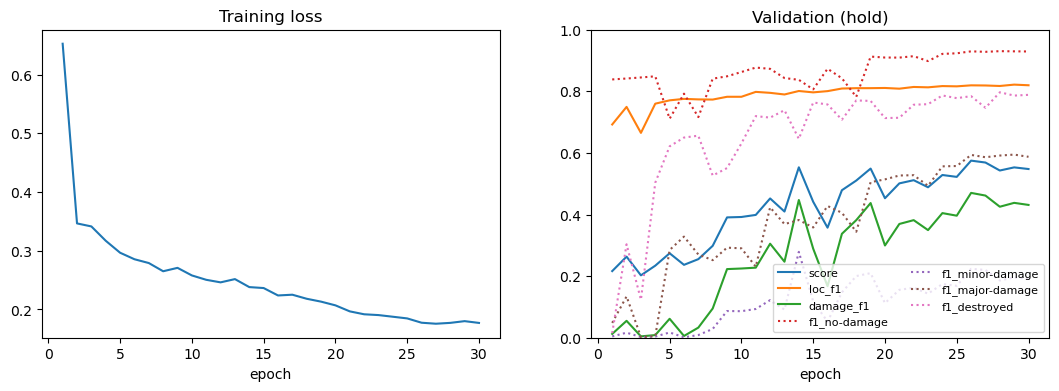

In [2]:
history = pd.read_csv(RUN_DIR / "history.csv")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.plot(history.epoch, history.train_loss)
ax1.set(title="Training loss", xlabel="epoch")
for col in ["score", "loc_f1", "damage_f1"] + [f"f1_{n}" for n in DAMAGE_NAMES]:
    ax2.plot(history.epoch, history[col], label=col, linestyle="-" if not col.startswith("f1_") else ":")
ax2.set(title="Validation (hold)", xlabel="epoch", ylim=(0, 1))
ax2.legend(fontsize=8, ncol=2)
fig.savefig(RUN_DIR / "curves.png", dpi=150, bbox_inches="tight")
history.tail()

## Building-level confusion matrix

Each true building gets the damage level most of its pixels were predicted as. Rows are the true level, columns the prediction. Takes a few minutes on all 933 validation tiles.

In [3]:
device = pick_device()
model = build_model(pretrained=False).to(device)
best = torch.load(RUN_DIR / "best.pt", map_location=device)
model.load_state_dict(best["model"])
model.eval()
print(f"best checkpoint: epoch {best['epoch'] + 1}, score {best['score']:.4f}")

val_ds = DamageDataset([DATA_ROOT / "hold"], crop=None, augment=False)
matrix = building_confusion(model, val_ds, device)
confusion = pd.DataFrame(matrix, index=[f"true {n}" for n in DAMAGE_NAMES], columns=[f"pred {n}" for n in DAMAGE_NAMES])
confusion.to_csv(RUN_DIR / "building_confusion.csv")
print(f"building-level accuracy: {np.trace(matrix) / matrix.sum():.3f}")
confusion

best checkpoint: epoch 26, score 0.5750


building-level accuracy: 0.784


,pred no-damage,pred minor-damage,pred major-damage,pred destroyed
true no-damage,21482,664,1089,376
true minor-damage,1516,917,1713,354
true major-damage,463,279,2472,394
true destroyed,352,109,261,2629


## Predictions on hurricane tiles

After image, true damage, predicted damage (colors as in notebook 01).

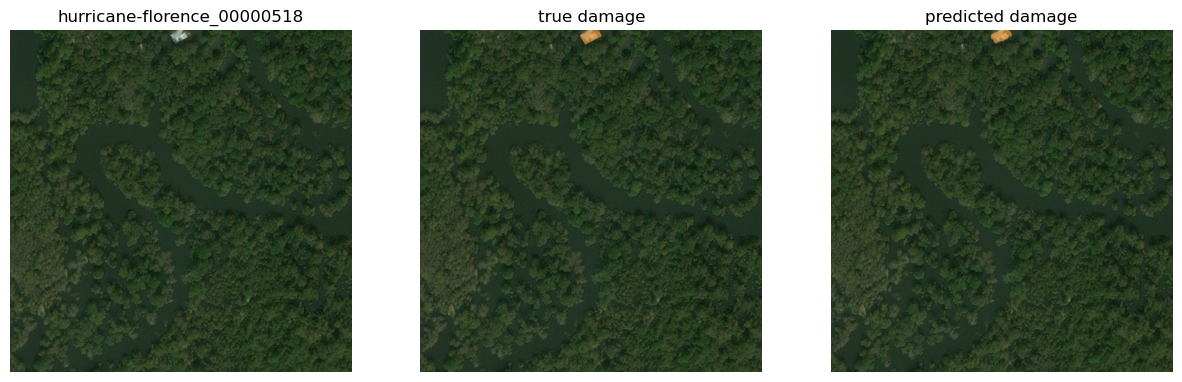

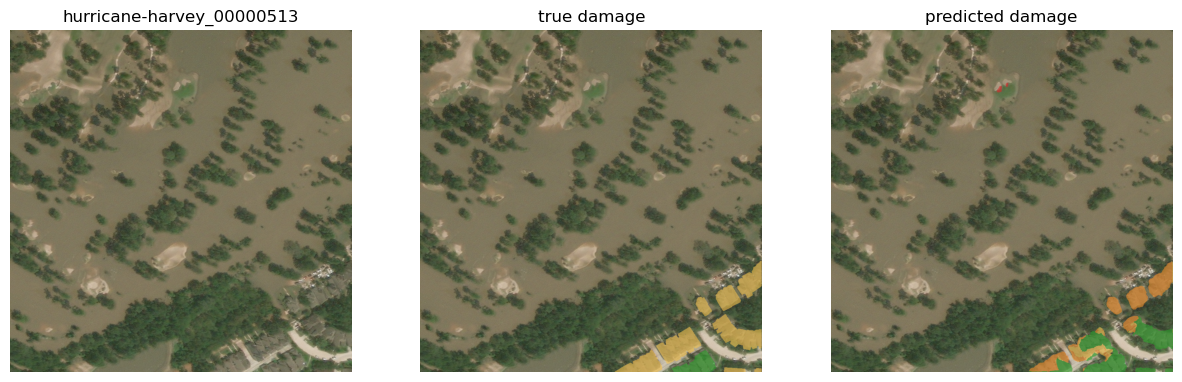

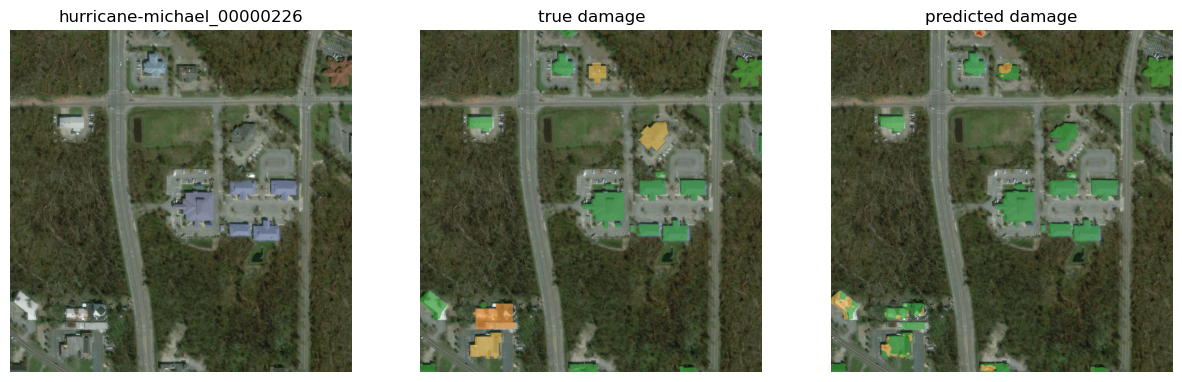

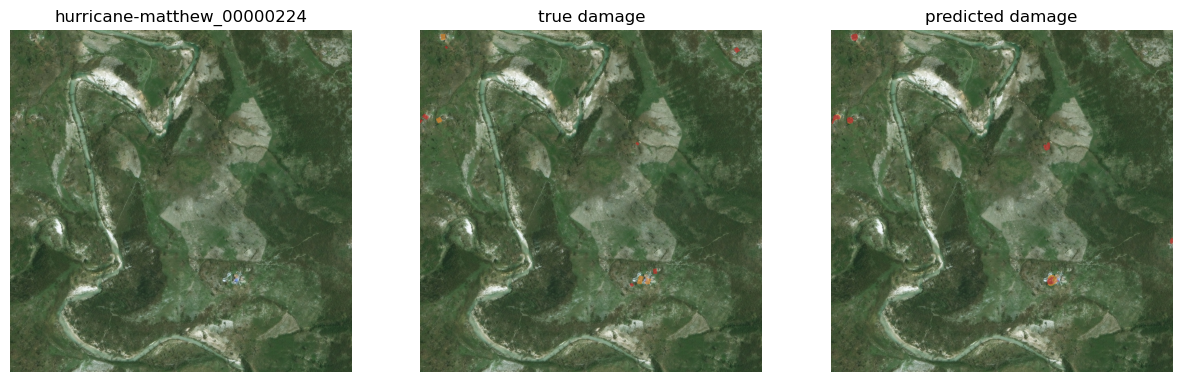

In [4]:
palette = np.array([[0, 0, 0]] + [plt.matplotlib.colors.to_rgb(DAMAGE_COLORS[n]) for n in DAMAGE_NAMES])

def colorize(classes, after):
    out = after.copy()
    sel = (classes >= 1) & (classes <= 4)
    out[sel] = 0.4 * after[sel] + 0.6 * palette[classes[sel]]
    return out

hurricane_idx = [i for i, p in enumerate(val_ds.mask_paths) if p.stem.startswith("hurricane")]
rng = np.random.default_rng(0)
for i in rng.choice(hurricane_idx, 4, replace=False):
    x, target = val_ds[i]
    with torch.no_grad():
        is_building, damage = predict_classes(model(x[None].to(device)))
    pred = np.where(is_building[0].cpu().numpy(), damage[0].cpu().numpy(), 0)
    after = (x[3:].numpy().transpose(1, 2, 0) * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406]).clip(0, 1)
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, img, title in zip(axes, [after, colorize(target.numpy(), after), colorize(pred, after)],
                              [val_ds.mask_paths[i].stem, "true damage", "predicted damage"]):
        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")
    plt.show()

## Results to record

- Best score / localization F1 / damage F1: ___ / ___ / ___
- Per-class F1 (no / minor / major / destroyed): ___
- Most common confusion (e.g. minor vs major): ___

For reference, the xView2 baseline released with the dataset scored about 0.27 overall, and the winning entry about 0.80.